# Домашнее задание 1 — персональные top-10 рекомендации
**Садаков Дмитрий Андреевич, Б05-331**

Датасет: **UCI Online Retail**. Задача — рекомендовать покупателю десять товаров,
которые он ещё не покупал. Сравниваются пять самостоятельно реализованных методов:
ItemKNN, iALS, EASE, FM с метапризнаками и ALS с собственным целевым сигналом.

Работа содержит код загрузки, EDA, глобальное временное разбиение, подбор на validation,
финальное сравнение на test и контрольные эксперименты. Все ячейки выполнены;
числа в таблицах получены запуском кода. Реализации находятся в `models/`.

## Как воспроизвести
Из корня репозитория, Python **3.10 или 3.11** (также проверено в текущем Python 3.9):
```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r hw1/requirements.txt
cd hw1
python run_notebook.py
```
Первый запуск скачивает официальный ZIP (около 23 MB) в `.cache/`, проверяет SHA-256
и читает XLSX. Следующие запуски используют локальный CSV-кеш. Данные в Git не входят.
Обучение работает на CPU; все конфигурации пересчитываются. Готовые таблицы в `results/`
не подменяют обучение. Для просмотра без Jupyter есть `experiments.html`.

Seed = 42. До подбора основной метрикой выбрана **NDCG@10**. Дополнительные:
Recall@10, Precision@10 и покрытие каталога. Test не участвует в выборе настроек.

In [1]:
import os
from pathlib import Path
os.environ.setdefault("MPLCONFIGDIR", str(Path(".cache/matplotlib").resolve()))
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
import sys, json, random, platform, time, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from data_utils import (load_raw, clean_data, split_data, build_training,
                        evaluation_cohort, TRAIN_END, VALID_END, SOURCE, DOWNLOAD)
from experiment import validation_search, final_comparison, SEARCH, PRIMARY, write_json
from models import ItemKNN, ImplicitALS, EASE, FactorizationMachine, CustomTargetALS
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
blas_limit = threadpool_limits(limits=1, user_api="blas")
Path("results").mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (11, 4), "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 110})
pd.set_option("display.max_colwidth", None)
environment = {"python": sys.version, "platform": platform.platform(), "seed": SEED,
               "torch_threads": torch.get_num_threads(), "blas_threads": 1,
               "packages": {name: importlib.metadata.version(name) for name in
                            ["numpy", "scipy", "pandas", "torch", "matplotlib", "openpyxl",
                             "nbformat", "nbclient", "nbconvert", "ipykernel", "threadpoolctl"]}}
write_json("results/environment.json", environment)
display(pd.Series(environment["packages"], name="version").to_frame())
print("Основная метрика:", PRIMARY, "; seed:", SEED)

,version
numpy,2.0.2
scipy,1.13.1
pandas,2.3.3
torch,2.8.0
matplotlib,3.9.4
openpyxl,3.1.5
nbformat,5.10.4
nbclient,0.10.2
nbconvert,7.17.1
ipykernel,6.31.0


Основная метрика: NDCG@10 ; seed: 42


## 1. Загрузка и описание данных
[Первоисточник UCI](https://archive.ics.uci.edu/dataset/352/online+retail),
[официальный архив](https://archive.ics.uci.edu/static/public/352/online+retail.zip),
[DOI: 10.24432/C5BW33](https://doi.org/10.24432/C5BW33).
Chen, D. (2015). *Online Retail*. Лицензия CC BY 4.0.

Проверена [ветка курса 26s-msai](https://github.com/girafe-ai/recsys/tree/26s-msai),
commit `38bb9fdfa190676d21a4fb68f50d721521ae59b7`. В доступных семинарах найдены
MovieLens, Last.fm, Retailrocket, VK-LSVD, Wikispeedia, Yambda и Criteo;
UCI Online Retail не обнаружен. Online Retail и Retailrocket — разные датасеты.
Подробности проверки приведены в `DATA.md`.

Это покупки в британском интернет-магазине за 01.12.2010–09.12.2011.
Одна исходная строка — позиция счёта, а не оценка пользователя.

| Поле | Значение и применение |
|---|---|
| CustomerID | Идентификатор покупателя, пользователь рекомендаций |
| StockCode | Артикул, рекомендуемый объект |
| InvoiceNo | Счёт; разные счета используются для числа повторных покупок |
| InvoiceDate | Время покупки; разбиение и давность покупок |
| Quantity | Количество единиц; очистка возвратов, EDA |
| UnitPrice | Цена за единицу в GBP; историческая медианная цена для FM |
| Description | Название товара; слова названия как метапризнаки FM |
| Country | Страна покупателя; исторический признак FM |

**Релевантность едина для всех моделей:** товар релевантен, если пользователь совершил
хотя бы одну положительную покупку этого товара в оцениваемом периоде, товар присутствовал
в обучающем каталоге и пользователь не покупал его до начала периода. Рейтинг, сумма
чека и собственный таргет ALS не меняют это определение. Мы решаем задачу открытия
новых товаров; повторное пополнение привычных покупок не входит в постановку.

In [2]:
raw, source_sha256 = load_raw()
print("Источник:", SOURCE)
print("SHA-256:", source_sha256)
print("Исходный размер:", raw.shape)
display(raw.head())
display(pd.DataFrame({"dtype": raw.dtypes.astype(str),
                      "missing": raw.isna().sum(),
                      "missing_share": raw.isna().mean()}))
print("Точные дубликаты:", raw.duplicated().sum())

Источник: https://archive.ics.uci.edu/dataset/352/online+retail
SHA-256: f5385cbb54bbebf7196389109c6b0621faab0c304e3702548165e71c84aede8b
Исходный размер: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,dtype,missing,missing_share
InvoiceNo,object,0,0.000000
StockCode,object,0,0.000000
Description,object,1454,0.002683
Quantity,int64,0,0.000000
InvoiceDate,datetime64[ns],0,0.000000
UnitPrice,float64,0,0.000000
CustomerID,float64,135080,0.249267
Country,object,0,0.000000


Точные дубликаты: 5268


## 2. EDA и подготовка
Удаляем точные дубликаты всех полей, строки без пользователя/товара/времени,
отмены (InvoiceNo начинается с C), неположительные Quantity и UnitPrice.
Возврат не считается положительной покупкой. Положительную историческую покупку
не удаляем задним числом по будущему возврату: это внесло бы будущую информацию.

Оставляем товарные артикулы вида `пять цифр + 0–2 буквы`. Таким образом исключаются
POST, D, M, DOT, BANK CHARGES и другие служебные позиции; правило может исключить
нетипичный реальный артикул, что является ограничением очистки. Пропуски названий
и страны заменяются UNKNOWN. Никакой случайной подвыборки и фильтрации по будущей
активности (например, k-core по всему периоду) нет: используется вся очищенная выборка.

Повторные покупки в разных счетах сохраняем как отдельные события. Для бинарной
матрицы X они объединяются в одну пару user–item; для confidence и собственного
таргета считаем **число различных счетов**, а не строк и не купленных единиц.

In [3]:
clean, cleaning_audit = clean_data(raw)
train, validation, test = split_data(clean)
display(cleaning_audit)
cleaning_audit.to_csv("results/cleaning.csv", index=False)
n_users, n_items = clean.CustomerID.nunique(), clean.StockCode.nunique()
n_pairs = len(clean[["CustomerID", "StockCode"]].drop_duplicates())
dataset_summary = {"raw_rows": len(raw), "clean_rows": len(clean), "users": n_users,
                   "items": n_items, "unique_user_item_pairs": n_pairs,
                   "sparsity": 1 - n_pairs/(n_users*n_items),
                   "source": SOURCE, "download": DOWNLOAD, "sha256": source_sha256}
write_json("results/dataset_summary.json", dataset_summary)
display(pd.Series(dataset_summary).to_frame("value"))
display(pd.DataFrame([{"split": name, "rows": len(part), "users": part.CustomerID.nunique(),
                       "items": part.StockCode.nunique(), "start": part.InvoiceDate.min(),
                       "end": part.InvoiceDate.max()}
                      for name, part in [("train", train), ("validation", validation), ("test", test)]]))
assert 100_000 <= len(clean) <= 2_000_000 and min(n_users, n_items) >= 1000
assert n_pairs >= 100_000  # Размер достаточен и при подсчёте уникальных пар.

,step,rows,users,items
0,Исходные строки,541909,4372,4070
1,Без точных дубликатов,536641,4372,4070
2,"Есть пользователь, товар и время",401604,4372,3684
3,Положительные покупки без отмен,392692,4338,3665
4,Только товарные артикулы,391150,4334,3659


,value
raw_rows,541909
clean_rows,391150
users,4334
items,3659
unique_user_item_pairs,266221
sparsity,0.983212
source,https://archive.ics.uci.edu/dataset/352/online+retail
download,https://archive.ics.uci.edu/static/public/352/online+retail.zip
sha256,f5385cbb54bbebf7196389109c6b0621faab0c304e3702548165e71c84aede8b


,split,rows,users,items,start,end
0,train,262637,3613,3502,2010-12-01 08:26:00,2011-09-30 15:52:00
1,validation,48611,1361,2617,2011-10-02 10:32:00,2011-10-31 17:13:00
2,test,79902,1904,2766,2011-11-01 08:16:00,2011-12-09 12:50:00


,user_unique_items,item_unique_users,item_median_price
count,3613.000000,3502.000000,3502.000000
mean,52.144755,53.797544,3.362797
std,72.177755,71.275264,6.914926
min,1.000000,1.000000,0.040000
25%,14.000000,8.000000,0.850000
50%,31.000000,28.000000,1.950000
75%,65.000000,70.000000,3.750000
max,1472.000000,750.000000,165.000000


Товаров с несколькими историческими названиями: 155
Доля строк train из UK: 0.8872


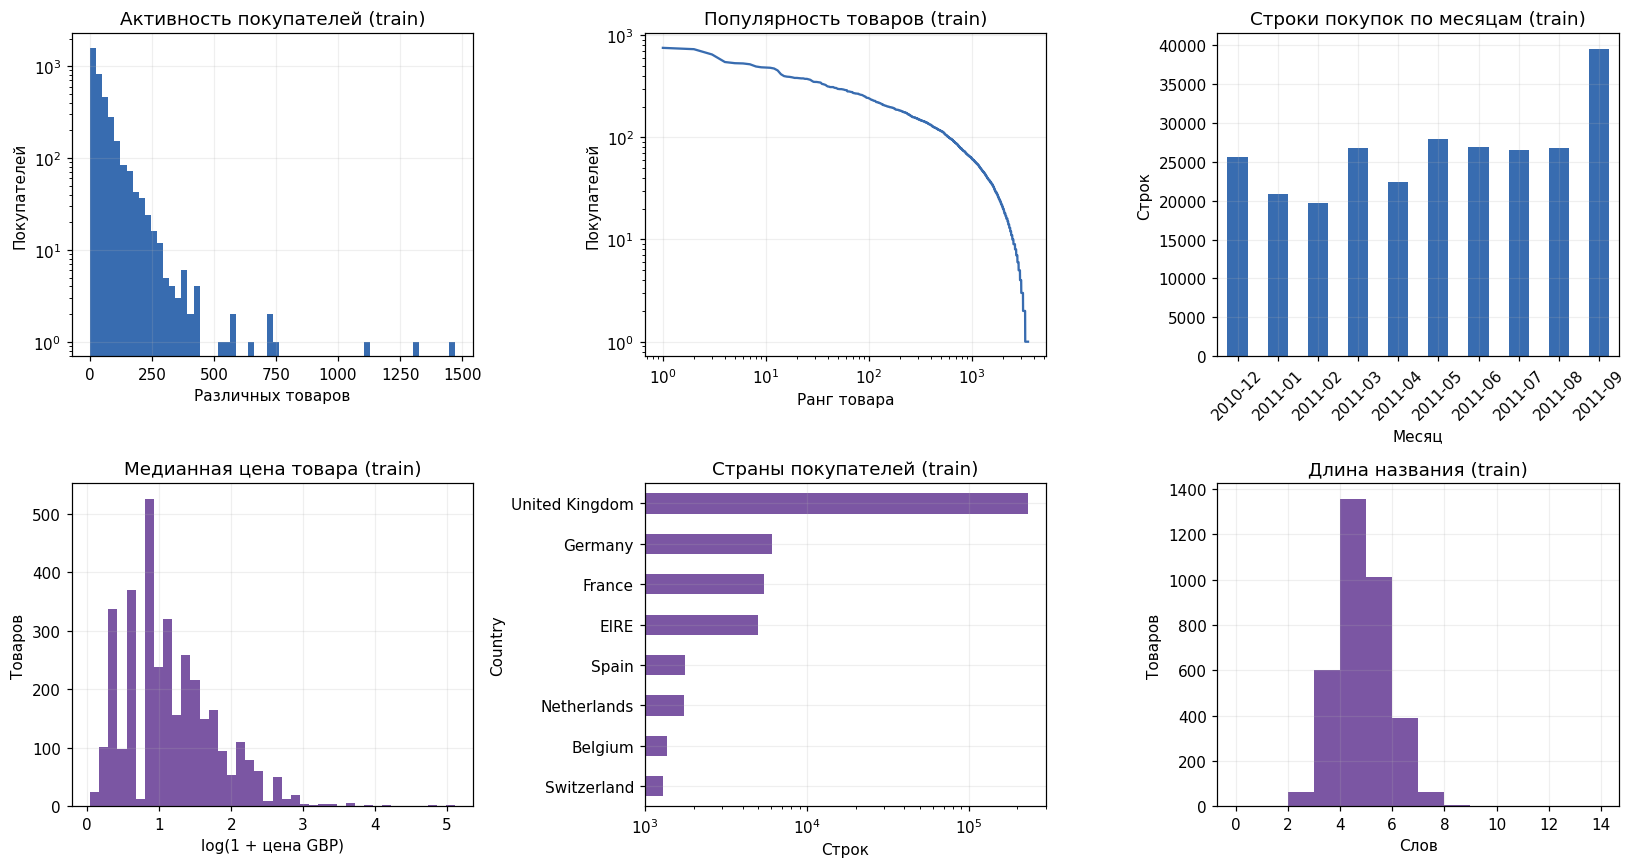

In [4]:
# Распределения и решения о признаках исследуем на train, без анализа test-качества.
activity = train.groupby("CustomerID").StockCode.nunique()
popularity = train.groupby("StockCode").CustomerID.nunique()
titles = train.groupby("StockCode").Description.nunique()
prices = train.groupby("StockCode").UnitPrice.median()
display(pd.DataFrame({"user_unique_items": activity.describe(),
                      "item_unique_users": popularity.describe(),
                      "item_median_price": prices.describe()}))
print("Товаров с несколькими историческими названиями:", int((titles > 1).sum()))
print("Доля строк train из UK:", round((train.Country == "United Kingdom").mean(), 4))
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes[0, 0].hist(activity, bins=60, color="#386cb0")
axes[0, 0].set(title="Активность покупателей (train)", xlabel="Различных товаров", ylabel="Покупателей", yscale="log")
axes[0, 1].plot(np.arange(1, len(popularity)+1), np.sort(popularity)[::-1], color="#386cb0")
axes[0, 1].set(title="Популярность товаров (train)", xlabel="Ранг товара", ylabel="Покупателей", xscale="log", yscale="log")
train.set_index("InvoiceDate").resample("MS").size().plot.bar(ax=axes[0, 2], color="#386cb0")
axes[0, 2].set(title="Строки покупок по месяцам (train)", xlabel="Месяц", ylabel="Строк")
axes[0, 2].set_xticklabels([str(x.date())[:7] for x in train.set_index("InvoiceDate").resample("MS").size().index], rotation=45)
axes[1, 0].hist(np.log1p(prices), bins=40, color="#7b56a3")
axes[1, 0].set(title="Медианная цена товара (train)", xlabel="log(1 + цена GBP)", ylabel="Товаров")
train.Country.value_counts().head(8).sort_values().plot.barh(ax=axes[1, 1], color="#7b56a3")
axes[1, 1].set(title="Страны покупателей (train)", xlabel="Строк", xscale="log")
token_counts = train.groupby("StockCode").Description.last().str.split().str.len()
axes[1, 2].hist(token_counts, bins=np.arange(0, 15), color="#7b56a3")
axes[1, 2].set(title="Длина названия (train)", xlabel="Слов", ylabel="Товаров")
fig.tight_layout()
fig.savefig("results/eda.png", dpi=160, bbox_inches="tight")
plt.show()

Наличие длинного хвоста популярности делает персонализацию нетривиальной:
популярные товары имеют больше совместных покупок, редкие — меньше обучающего сигнала.
Большая разреженность мотивирует регуляризацию ALS/EASE и использование метаданных.
Страна сильно несбалансирована, поэтому нельзя ожидать большого эффекта только от неё.
Названия и цены могут меняться: признаки фиксируются по истории до соответствующей
границы обучения, а не по последнему значению во всём датасете.

## 3. Протокол оценки
- **Train:** время строго меньше 01.10.2011.
- **Validation:** 01.10.2011 ≤ время < 01.11.2011.
- **Test:** время ≥ 01.11.2011, до конца файла 09.12.2011.

Это глобальные календарные границы: события из будущего другого пользователя
не попадают в обучение. Настройки выбираются по macro NDCG@10 на validation.
Затем все выбранные модели заново обучаются на train+validation, все признаки
пересчитываются только по этому периоду, и один раз оцениваются на test.

**Кандидаты:** весь каталог обучающего периода за вычетом всех уже купленных данным
пользователем товаров; отрицательное семплирование при оценке отсутствует.
Товары, появившиеся только в held-out периоде, недоступны моделям. Пользователей
без обучающей истории исключаем. Также исключаем пользователей без хотя бы одного
доступного нового релевантного товара. Числа исключений выводятся явно.
Это условная оценка для warm-start; cold-start результатами не покрывается.

Все пять методов и обе абляции на каждом этапе используют один объект данных,
один словарь релевантности, один список пользователей и одни маски известных товаров.
Если scores совпали, выбирается меньший StockCode в лексикографическом порядке.
Наборы пользователей validation и test естественно различаются, но внутри каждого
этапа они строго одинаковы для всех методов. Отдельное исключение при <10 кандидатах
также общее и учитывается в отчёте.

In [5]:
train_data = build_training(train, TRAIN_END)
valid_truth, valid_cohort = evaluation_cohort(train_data, validation)
display(pd.Series(valid_cohort).to_frame("validation"))
display(pd.Series(train_data.feature_summary).to_frame("FM train features"))
print("Бинарная train-матрица:", train_data.x.shape, "; nnz:", train_data.x.nnz)
print("Разреженность train:", 1 - train_data.x.nnz/np.prod(train_data.x.shape))
write_json("results/validation_cohort.json", valid_cohort)

,validation
heldout_rows,48611
heldout_users,1361
heldout_unique_pairs,44190
cold_user_pairs,10699
cold_item_pairs,1793
cold_user_or_item_pairs,12199
seen_pairs_excluded,11709
evaluated_users,937
evaluated_relevant_pairs,20282
users_with_fewer_than_k_candidates,0


,FM train features
countries,36
price_bins,5
title_vocabulary,512
title_words_max,6
price_log_boundaries,"[0.6151856390902335, 0.8960880245566356, 1.2669476034873244, 1.6582280766035324]"
fitted_before,2011-10-01 00:00:00


Бинарная train-матрица: (3613, 3502) ; nnz: 188399
Разреженность train: 0.9851100071241565


### Метрики, выбранные до подбора
Пусть $R_u$ — множество релевантных новых товаров, $L_u$ — упорядоченные 10 рекомендаций,
$h_{ur}=\mathbf1[L_{ur}\in R_u]$.

$$\operatorname{Recall@10}(u)=\frac{\sum_{r=1}^{10}h_{ur}}{|R_u|},\qquad
\operatorname{Precision@10}(u)=\frac{\sum_{r=1}^{10}h_{ur}}{10}.$$
$$\operatorname{NDCG@10}(u)=
\frac{\sum_{r=1}^{10}h_{ur}/\log_2(r+1)}
{\sum_{r=1}^{\min(10,|R_u|)}1/\log_2(r+1)}.$$

**NDCG@10 — основная:** полезные товары должны находиться выше на экране, а нормировка
учитывает разное число релевантных объектов. **Recall@10:** какую долю будущего интереса
покупателя удалось покрыть десятью местами. Precision дополняет её долей полезных мест.
Для всех трёх берём среднее по пользователям, поэтому активные покупатели не получают
большего веса. **Coverage@10** — доля каталога, хотя бы раз попавшая в рекомендации;
это характеристика разнообразия выдачи между пользователями, а не точности.

## 4. Модели и подбор настроек
В `models/` по отдельному файлу на каждый метод. Разрешённые библиотеки используются
для матричных операций и autodiff; готовые рекомендательные модели и обучаемые
алгоритмы из sklearn/implicit/LightFM/RecBole не используются.

### 4.1 ItemKNN — коллаборативные соседи товаров
Для бинарной матрицы $X$ считаем совместные покупки и сглаженный косинус:
$$s_{ij}=\frac{x_i^T x_j}{\|x_i\|_2\|x_j\|_2+\beta},\quad s_{ii}=0.$$
В каждом столбце целевого товара $j$ оставляем $k$ наиболее похожих соседей.
Score пользователя: $\hat r_{uj}=\sum_{i:X_{ui}=1}s_{ij}$. Параметр $\beta$
снижает влияние случайных совпадений у редких товаров. Сходство, усечение соседей,
scores и top-10 реализованы самостоятельно.

### 4.2 Базовый iALS
$n_{ui}$ — число различных счетов с товаром. Для наблюдавшихся пар $p_{ui}=1$,
$c_{ui}=1+\alpha\log(1+n_{ui})$; для остальных $p_{ui}=0,c_{ui}=1$.
$$\min_{A,B}\sum_{u,i}c_{ui}(p_{ui}-a_u^Tb_i)^2+
\lambda\left(\sum_u\|a_u\|^2+\sum_i\|b_i\|^2\right).$$
Каждый шаг пользователя решает систему
$$\left[B^TB+\sum_{i\in I_u}(c_{ui}-1)b_ib_i^T+\lambda I\right]a_u
=\sum_{i\in I_u}c_{ui}p_{ui}b_i.$$
Шаг товаров симметричен. Используем разложение Холецкого; ненаблюдавшиеся пары
учитываются через $B^TB$, а не игнорируются. Предсказание $a_u^Tb_i$.

### 4.3 EASE
$$\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\quad\operatorname{diag}(W)=0.$$
При $P=(X^TX+\lambda I)^{-1}$ имеем $W_{ij}=-P_{ij}/P_{jj}$ для $i\ne j$,
$W_{ii}=0$. Предсказания $XW$. Нулевая диагональ предотвращает прямое копирование
входного товара. Обратную матрицу получаем решением системы с единичной правой частью.

### 4.4 FM с метапризнаками
Для разреженного вектора признаков $z$ реализована факторизационная машина второго порядка:
$$f(z)=w_0+\sum_j w_jz_j+\frac12\sum_{d=1}^D
\left[\left(\sum_jv_{jd}z_j\right)^2-\sum_jv_{jd}^2z_j^2\right].$$
Категориальные признаки кодируются единицами, отсутствующие слова — нулевым padding.
Используются user ID, item ID и дополнительные поля:
1. Последняя известная страна пользователя — возможные различия вкусов и доставки.
2. Квинтиль исторической медианной цены товара — ценовой сегмент. Границы квинтилей
   вычисляются по log(1+price) только на обучающем каталоге.
3. До шести разных слов последнего известного названия товара — тематика и тип товара.
   Словарь: не более 512 слов длины ≥3, встречающихся хотя бы у трёх товаров train.

Данные будущей покупки (её Quantity, цена конкретной строки, страна из будущей строки)
не используются. Нет обучения словаря по validation/test. В refit словарь, цены и страны
перестраиваются на train+validation — информации, уже доступной на 01.11.2011.

Обучение: бинарная логистическая функция потерь, Adam, L2-регуляризация параметров
(weight decay). Каждая известная пара — положительный пример. На каждую положительную
пару в каждой эпохе генерируются 3 равномерных отрицательных товара из **неизвестных
в обучении** этому пользователю. Validation/test не используются даже для исключения
ложных negatives. Scores ранжируются без sigmoid, так как она монотонна.
Эти scores не интерпретируются как калиброванные вероятности реальной покупки.

### 4.5 ALS с собственным целевым сигналом
Покупки содержат интенсивность и давность интереса. Однако количество единиц может
отражать оптовый заказ, поэтому используем число **разных счетов**, а не Quantity.
Пусть $\Delta_{ui}$ — число дней от последней покупки до границы обучения. Определим
$$p^{\mathrm{custom}}_{ui}=
\left[0.6+0.4\left(1-\exp\left(-\frac{n_{ui}-1}{2}\right)\right)\right]
\left[0.5+0.5\exp\left(-\frac{\Delta_{ui}}{90}\right)\right]$$
для известных пар, и 0 для остальных. Первая скобка повышает сигнал повторного интереса
с насыщением; вторая ослабляет устаревший интерес, сохраняя половину веса исторического
сигнала. Одиночная недавняя покупка даёт примерно 0.6, давняя — примерно 0.3;
несколько недавних покупок приближают таргет к 1. Это гипотеза о полезности истории,
а не утверждение, что выбранная формула обязательно улучшит качество.

Целевая функция и ALS-шаги те же, но в правой части системы стоит
$c_{ui}p^{\mathrm{custom}}_{ui}$. **Матрица confidence полностью совпадает с базовой**.
Следовательно, меняются сами аппроксимируемые значения, а не только веса ошибок.
Константы 0.6, 0.4, 0.5, 2 и 90 дней зафиксированы до поиска; 90 дней задают
плавный квартальный масштаб забывания. Они не подбираются по test.

Для честного сравнения выполнены: (а) одинаковый поиск ранга и регуляризации у двух ALS;
(б) дополнительный CustomALS_matched с **теми же выбранными настройками**, что у iALS.
Контроль FM_ID_only использует выбранные настройки FM и меняет только наличие метаданных.
Обе абляции объявлены до просмотра test и не считаются отдельными основными моделями.

In [6]:
from checks import NumericalChecks
import unittest
suite = unittest.defaultTestLoader.loadTestsFromTestCase(NumericalChecks)
checks_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert checks_result.wasSuccessful()

test_als_update_matches_dense_weighted_problem (checks.NumericalChecks) ... 

ok
test_custom_target_changes_preferences (checks.NumericalChecks) ... 

ok
test_ease_constrained_normal_equations (checks.NumericalChecks) ... 

ok
test_fm_equals_explicit_pair_sum (checks.NumericalChecks) ... 

ok
test_item_cosine_direction (checks.NumericalChecks) ... 

ok
test_metrics_hand_example (checks.NumericalChecks) ... 

ok
test_seen_exclusion_and_deterministic_ties (checks.NumericalChecks) ... 

ok

----------------------------------------------------------------------
Ran 7 tests in 0.118s

OK


In [7]:
search_table = pd.DataFrame([{"model": name, "configurations": len(configs),
                              "search_space": json.dumps(configs, ensure_ascii=False)}
                             for name, configs in SEARCH.items()])
display(search_table)
print("Итого конфигураций:", sum(map(len, SEARCH.values())))

,model,configurations,search_space
0,ItemKNN,4,"[{""neighbors"": 40, ""shrink"": 10.0}, {""neighbors"": 40, ""shrink"": 100.0}, {""neighbors"": 100, ""shrink"": 10.0}, {""neighbors"": 100, ""shrink"": 100.0}]"
1,iALS,4,"[{""factors"": 32, ""regularization"": 1.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}, {""factors"": 32, ""regularization"": 10.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}, {""factors"": 64, ""regularization"": 1.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}, {""factors"": 64, ""regularization"": 10.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}]"
2,EASE,3,"[{""regularization"": 100.0}, {""regularization"": 500.0}, {""regularization"": 1000.0}]"
3,FM,4,"[{""factors"": 16, ""epochs"": 6, ""learning_rate"": 0.01, ""regularization"": 1e-05, ""negatives"": 3, ""batch_size"": 8192, ""seed"": 42, ""metadata"": true}, {""factors"": 16, ""epochs"": 12, ""learning_rate"": 0.01, ""regularization"": 1e-05, ""negatives"": 3, ""batch_size"": 8192, ""seed"": 42, ""metadata"": true}, {""factors"": 32, ""epochs"": 6, ""learning_rate"": 0.01, ""regularization"": 1e-05, ""negatives"": 3, ""batch_size"": 8192, ""seed"": 42, ""metadata"": true}, {""factors"": 32, ""epochs"": 12, ""learning_rate"": 0.01, ""regularization"": 1e-05, ""negatives"": 3, ""batch_size"": 8192, ""seed"": 42, ""metadata"": true}]"
4,CustomALS,4,"[{""factors"": 32, ""regularization"": 1.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}, {""factors"": 32, ""regularization"": 10.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}, {""factors"": 64, ""regularization"": 1.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}, {""factors"": 64, ""regularization"": 10.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}]"


Итого конфигураций: 19


Полная сетка: ItemKNN — neighbors ∈ {40,100}, shrink ∈ {10,100}; EASE — λ ∈ {100,500,1000};
оба ALS — factors ∈ {32,64}, λ ∈ {1,10}, α=20, 10 итераций; FM — factors ∈ {16,32},
epochs ∈ {6,12}, learning_rate=0.01, L2=10⁻⁵, 3 negatives, batch_size=8192.
Всего **19 конфигураций**. Сетка компактная из-за CPU-ресурсов; одинаковое число попыток
не означает одинаковую вычислительную стоимость. Для одинакового NDCG выбирается
первая конфигурация в фиксированном порядке сетки. Настройки сохраняются
в `results/selected_params.json` **до** финального обучения и оценки.

In [8]:
validation_results, selected = validation_search(train_data, valid_truth)
display(validation_results[["model", "trial", "NDCG@10", "Recall@10", "Precision@10",
                            "Coverage@10", "fit_seconds", "params"]])
display(pd.DataFrame([{"model": name, "chosen_parameters": json.dumps(params, ensure_ascii=False)}
                      for name, params in selected.items()]))

ItemKNN 1/4: NDCG=0.087253, Recall=0.051310, fit=1.1s


ItemKNN 2/4: NDCG=0.091244, Recall=0.052665, fit=1.1s


ItemKNN 3/4: NDCG=0.089847, Recall=0.054548, fit=1.1s


ItemKNN 4/4: NDCG=0.093688, Recall=0.053717, fit=1.3s


/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:22: RuntimeWarning: divide by zero encountered in matmul
  baseline = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:22: RuntimeWarning: overflow encountered in matmul
  baseline = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:22: RuntimeWarning: invalid value encountered in matmul
  baseline = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:30: RuntimeWarning: divide by zero encountered in matmul
  a = baseline + (y.T * (c - 1.0)) @ y
/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:30: RuntimeWarning: overflow encountered in matmul
  a = baseline + (y.T * (c - 1.0)) @ y
/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:30: RuntimeWarning: invalid value encountered in matmul
  a = baseline + (y.T * (c - 1.0)) @ y
/Users/d.

...

CustomALS 2/4: NDCG=0.081259, Recall=0.052246, fit=2.2s


CustomALS 3/4: NDCG=0.077348, Recall=0.051273, fit=3.7s


CustomALS 4/4: NDCG=0.081679, Recall=0.053182, fit=4.3s


,model,trial,NDCG@10,Recall@10,Precision@10,Coverage@10,fit_seconds,params
0,ItemKNN,1,0.087253,0.051310,0.072145,0.318961,1.109802,"{""neighbors"": 40, ""shrink"": 10.0}"
1,ItemKNN,2,0.091244,0.052665,0.075027,0.239292,1.064303,"{""neighbors"": 40, ""shrink"": 100.0}"
2,ItemKNN,3,0.089847,0.054548,0.073212,0.287264,1.115025,"{""neighbors"": 100, ""shrink"": 10.0}"
3,ItemKNN,4,0.093688,0.053717,0.075027,0.212164,1.299730,"{""neighbors"": 100, ""shrink"": 100.0}"
4,iALS,1,0.074197,0.044887,0.060299,0.297830,2.361804,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 10, ""regularization"": 1.0, ""seed"": 42}"
5,iALS,2,0.074499,0.046942,0.061793,0.282125,2.294421,"{""alpha"": 20.0, ""factors"": 32, ""iterations"": 10, ""regularization"": 10.0, ""seed"": 42}"
6,iALS,3,0.073617,0.045852,0.062220,0.325243,3.865642,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 10, ""regularization"": 1.0, ""seed"": 42}"
7,iALS,4,0.075351,0.046299,0.062753,0.317247,3.802763,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 10, ""regularization"": 10.0, ""seed"": 42}"
8,EASE,1,0.094050,0.061128,0.078335,0.294689,4.482978,"{""regularization"": 100.0}"
9,EASE,2,0.096192,0.058764,0.080149,0.231011,4.434946,"{""regularization"": 500.0}"


,model,chosen_parameters
0,ItemKNN,"{""neighbors"": 100, ""shrink"": 100.0}"
1,iALS,"{""factors"": 64, ""regularization"": 10.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}"
2,EASE,"{""regularization"": 500.0}"
3,FM,"{""factors"": 32, ""epochs"": 12, ""learning_rate"": 0.01, ""regularization"": 1e-05, ""negatives"": 3, ""batch_size"": 8192, ""seed"": 42, ""metadata"": true}"
4,CustomALS,"{""factors"": 64, ""regularization"": 10.0, ""alpha"": 20.0, ""iterations"": 10, ""seed"": 42}"


## 5. Финальное сравнение на test
С этого места настройки зафиксированы. Обучаем каждую выбранную модель на
train+validation. Ни test-таргеты, ни будущие метаданные не передаются в `fit`.
Для test маскируются все покупки train+validation, включая товары validation.

In [9]:
assert set(selected) == {"ItemKNN", "iALS", "EASE", "FM", "CustomALS"}
assert json.loads(Path("results/selected_params.json").read_text()) == selected
refit_frame = pd.concat([train, validation], ignore_index=True)
final_data = build_training(refit_frame, VALID_END)
test_truth, test_cohort = evaluation_cohort(final_data, test)
display(pd.Series(test_cohort).to_frame("test"))
write_json("results/test_cohort.json", test_cohort)
write_json("results/final_feature_summary.json", final_data.feature_summary)
print("Граница всех финальных признаков:", final_data.feature_summary["fitted_before"])

,test
heldout_rows,79902
heldout_users,1904
heldout_unique_pairs,67524
cold_user_pairs,11888
cold_item_pairs,733
cold_user_or_item_pairs,12541
seen_pairs_excluded,22183
evaluated_users,1440
evaluated_relevant_pairs,32800
users_with_fewer_than_k_candidates,0


Граница всех финальных признаков: 2011-11-01 00:00:00


In [10]:
test_results, comparisons, examples, losses = final_comparison(
    final_data, test_truth, selected, validation_results)
main_results = test_results.loc[test_results.role == "main"].sort_values("NDCG@10", ascending=False)
display(main_results[["model", "NDCG@10", "Recall@10", "Precision@10", "Coverage@10",
                      "validation_NDCG@10", "fit_seconds", "ranking_seconds", "params"]])
assert (test_results.users == len(test_truth)).all()

TEST ItemKNN: NDCG=0.090471, Recall=0.053777


/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:22: RuntimeWarning: divide by zero encountered in matmul
  baseline = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:22: RuntimeWarning: overflow encountered in matmul
  baseline = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:22: RuntimeWarning: invalid value encountered in matmul
  baseline = fixed.T @ fixed + self.regularization * np.eye(self.factors)
/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:30: RuntimeWarning: divide by zero encountered in matmul
  a = baseline + (y.T * (c - 1.0)) @ y
/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:30: RuntimeWarning: overflow encountered in matmul
  a = baseline + (y.T * (c - 1.0)) @ y
/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:30: RuntimeWarning: invalid value encountered in matmul
  a = baseline + (y.T * (c - 1.0)) @ y
/Users/d.

/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:53: RuntimeWarning: divide by zero encountered in matmul
  return self.users[users] @ self.items.T
/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:53: RuntimeWarning: overflow encountered in matmul
  return self.users[users] @ self.items.T
/Users/d.sadakov/Documents/MIPT/ML/hw1/models/ials.py:53: RuntimeWarning: invalid value encountered in matmul
  return self.users[users] @ self.items.T


TEST iALS: NDCG=0.082293, Recall=0.051544


TEST EASE: NDCG=0.102854, Recall=0.063238


TEST FM: NDCG=0.073819, Recall=0.044217


TEST CustomALS: NDCG=0.087730, Recall=0.056000


TEST FM_ID_only: NDCG=0.076889, Recall=0.042804


TEST CustomALS_matched: NDCG=0.087730, Recall=0.056000


,model,NDCG@10,Recall@10,Precision@10,Coverage@10,validation_NDCG@10,fit_seconds,ranking_seconds,params
2,EASE,0.102854,0.063238,0.083681,0.278625,0.096192,5.215179,5.298790,"{""regularization"": 500.0}"
0,ItemKNN,0.090471,0.053777,0.074097,0.263100,0.093688,1.445319,0.810240,"{""neighbors"": 100, ""shrink"": 100.0}"
4,CustomALS,0.087730,0.056000,0.070903,0.304685,0.081679,3.893230,0.569517,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 10, ""regularization"": 10.0, ""seed"": 42}"
1,iALS,0.082293,0.051544,0.067361,0.354311,0.075351,4.275131,0.660857,"{""alpha"": 20.0, ""factors"": 64, ""iterations"": 10, ""regularization"": 10.0, ""seed"": 42}"
3,FM,0.073819,0.044217,0.062708,0.236762,0.073602,17.397857,2.246938,"{""batch_size"": 8192, ""epochs"": 12, ""factors"": 32, ""learning_rate"": 0.01, ""metadata"": true, ""negatives"": 3, ""regularization"": 1e-05, ""seed"": 42}"


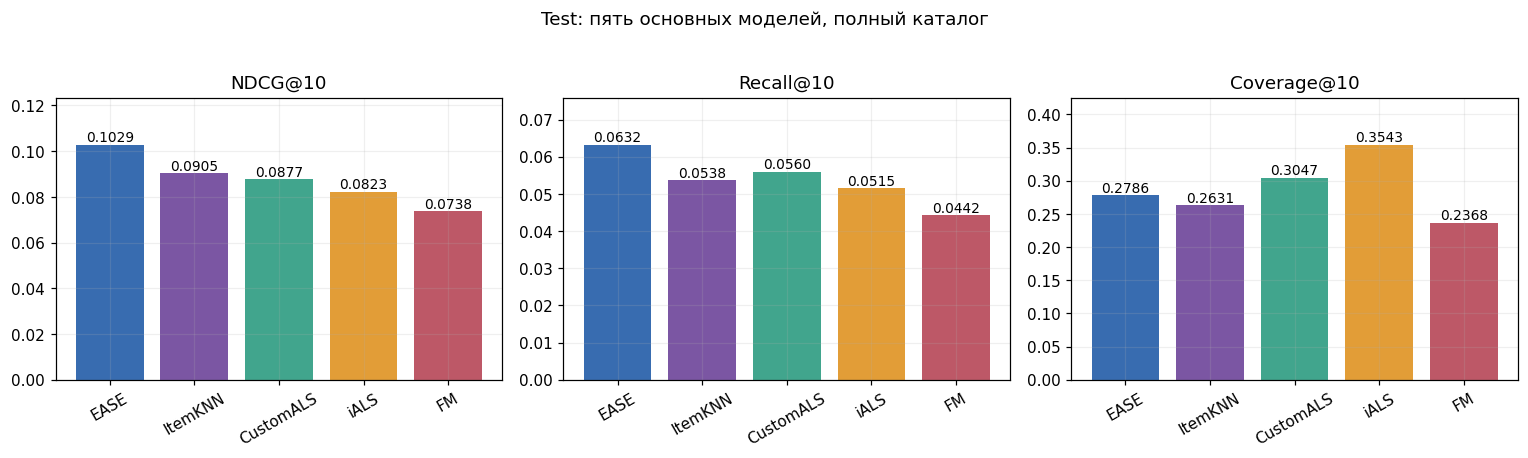

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["NDCG@10", "Recall@10", "Coverage@10"]):
    ax.bar(main_results.model, main_results[metric], color=["#386cb0", "#7b56a3", "#41a58d", "#e29d37", "#bd5867"])
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=30)
    for j, value in enumerate(main_results[metric]):
        ax.text(j, value, f"{value:.4f}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(0, main_results[metric].max()*1.2)
fig.suptitle("Test: пять основных моделей, полный каталог", y=1.03)
fig.tight_layout()
fig.savefig("results/test_metrics.png", dpi=160, bbox_inches="tight")
plt.show()

### Контроль влияния метаданных и собственного таргета
FM_ID_only отличается от основной FM только удалением страны, ценового сегмента
и слов названия; выбранные rank/epochs/learning rate/negatives совпадают.
CustomALS_matched использует настройки, выбранные для базового iALS, поэтому
изменение качества в этом сравнении обусловлено изменением целевого сигнала
в рамках фиксированной процедуры обучения. Независимо подобранный CustomALS
также приведён в основной таблице.

Для разностей macro-метрик строится парный bootstrap по одинаковым test-пользователям:
2000 выборок с возвращением, seed=42, перцентили 2.5% и 97.5%. Интервал описывает
вариацию по пользователям при фиксированном обучении; он не учитывает выбор датасета,
сезонность, поиск гиперпараметров и разные случайные инициализации.

,model,role,NDCG@10,Recall@10,Coverage@10
0,ItemKNN,main,0.090471,0.053777,0.263100
1,iALS,main,0.082293,0.051544,0.354311
2,EASE,main,0.102854,0.063238,0.278625
3,FM,main,0.073819,0.044217,0.236762
4,CustomALS,main,0.087730,0.056000,0.304685
5,FM_ID_only,ablation,0.076889,0.042804,0.175769
6,CustomALS_matched,ablation,0.087730,0.056000,0.304685


,comparison,metric,mean_difference,ci95_low,ci95_high
0,CustomALS minus iALS,NDCG@10,0.005437,-0.000174,0.011201
1,CustomALS minus iALS,Recall@10,0.004456,-0.000902,0.009769
2,CustomALS_matched minus iALS,NDCG@10,0.005437,-0.000174,0.011201
3,CustomALS_matched minus iALS,Recall@10,0.004456,-0.000902,0.009769
4,FM minus FM_ID_only,NDCG@10,-0.003070,-0.008330,0.002883
5,FM minus FM_ID_only,Recall@10,0.001413,-0.003216,0.005991


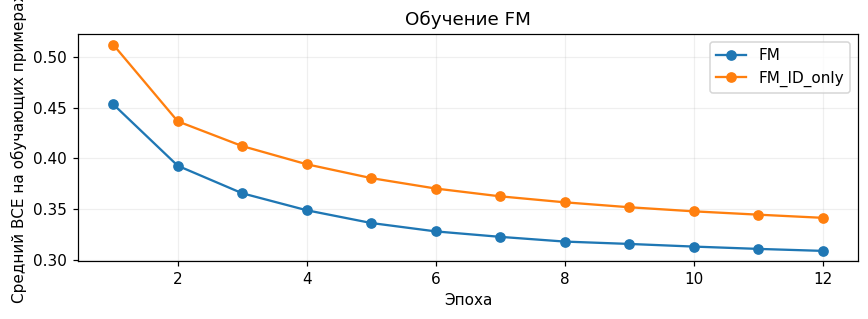

In [12]:
display(test_results[["model", "role", "NDCG@10", "Recall@10", "Coverage@10"]])
ci_rows = [{"comparison": name, "metric": metric, **stats}
           for name, metrics in comparisons.items() for metric, stats in metrics.items()]
ci_table = pd.DataFrame(ci_rows)
display(ci_table)
ci_table.to_csv("results/paired_comparisons.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 3))
for name, values in losses.items():
    ax.plot(np.arange(1, len(values)+1), values, marker="o", label=name)
ax.set(xlabel="Эпоха", ylabel="Средний BCE на обучающих примерах", title="Обучение FM")
ax.legend()
fig.tight_layout()
fig.savefig("results/fm_training.png", dpi=160, bbox_inches="tight")
plt.show()

### Пример персональных рекомендаций
Показываем первый по внутреннему ID test-профиль (без отбора по качеству) и модель,
выбранную по validation. Метка `relevant_in_test` добавлена только для анализа после
генерации рекомендаций и не является входным признаком.

In [13]:
best_validation_model = validation_results.groupby("model")[PRIMARY].max().idxmax()
example_user = sorted(test_truth)[0]
example_original_id = final_data.users[example_user]
print("Пользователь:", example_original_id, "; модель по validation:", best_validation_model)
history = refit_frame.loc[refit_frame.CustomerID == example_original_id,
                          ["InvoiceDate", "StockCode", "Description"]].tail(10)
display(history)
display(pd.DataFrame(examples[f"{best_validation_model}:{example_original_id}"]))

Пользователь: 12347 ; модель по validation: EASE


,InvoiceDate,StockCode,Description
310087,2011-10-31 12:25:00,23480,MINI LIGHTS WOODLAND MUSHROOMS
310088,2011-10-31 12:25:00,23503,PLAYING CARDS KEEP CALM & CARRY ON
310089,2011-10-31 12:25:00,23506,MINI PLAYING CARDS SPACEBOY
310090,2011-10-31 12:25:00,23508,MINI PLAYING CARDS DOLLY GIRL
310091,2011-10-31 12:25:00,47559B,TEA TIME OVEN GLOVE
310092,2011-10-31 12:25:00,47567B,TEA TIME KITCHEN APRON
310093,2011-10-31 12:25:00,47580,TEA TIME DES TEA COSY
310094,2011-10-31 12:25:00,84558A,3D DOG PICTURE PLAYING CARDS
310095,2011-10-31 12:25:00,84991,60 TEATIME FAIRY CAKE CASES
310096,2011-10-31 12:25:00,84992,72 SWEETHEART FAIRY CAKE CASES


,rank,stock_code,title,relevant_in_test
0,1,21977,PACK OF 60 PINK PAISLEY CAKE CASES,False
1,2,22730,ALARM CLOCK BAKELIKE IVORY,False
2,3,23245,SET OF 3 REGENCY CAKE TINS,False
3,4,21212,PACK OF 72 RETROSPOT CAKE CASES,False
4,5,84997A,CHILDRENS CUTLERY POLKADOT GREEN,False
5,6,22951,60 CAKE CASES DOLLY GIRL DESIGN,False
6,7,21790,VINTAGE SNAP CARDS,False
7,8,84378,SET OF 3 HEART COOKIE CUTTERS,False
8,9,21213,PACK OF 72 SKULL CAKE CASES,False
9,10,23148,MINIATURE ANTIQUE ROSE HOOK IVORY,False


## 6. Выводы
Следующий блок формирует численные выводы из реально полученных таблиц.
Выбор настроек заканчивается до test; итоговая расстановка моделей на test
используется для отчёта, а не для повторного подбора.

In [14]:
scores = test_results.set_index("model")
winner = main_results.iloc[0]
val_winner = validation_results.groupby("model")[PRIMARY].max().idxmax()
lines = [f"**Лучший результат среди пяти моделей на test:** {winner['model']}: "
         f"NDCG@10 = {winner['NDCG@10']:.5f}, Recall@10 = {winner['Recall@10']:.5f}, "
         f"Precision@10 = {winner['Precision@10']:.5f}. "
         f"По validation до открытия test выбиралась модель {val_winner}.",
         "**Выбранные настройки:** " + "; ".join(
             f"{name}: `{json.dumps(params, ensure_ascii=False)}`" for name, params in selected.items()) + "."]
for left, right, label in [("CustomALS", "iALS", "Собственный таргет после одинакового поиска"),
                            ("CustomALS_matched", "iALS", "Собственный таргет при настройках базового ALS"),
                            ("FM", "FM_ID_only", "Метаданные FM при фиксированных настройках")]:
    stats = comparisons[f"{left} minus {right}"]["NDCG@10"]
    delta = stats["mean_difference"]
    direction = "положительна" if delta > 0 else "отрицательна"
    evidence = ("Интервал не включает ноль." if stats['ci95_low'] > 0 or stats['ci95_high'] < 0
                else "Интервал включает ноль: надёжного направления эффекта по этому bootstrap нет.")
    lines.append(f"**{label}:** {left} — {scores.loc[left, 'NDCG@10']:.5f}, "
                 f"{right} — {scores.loc[right, 'NDCG@10']:.5f}. Наблюдаемая разность {direction}: "
                 f"ΔNDCG@10 = {delta:+.5f}, 95% CI "
                 f"[{stats['ci95_low']:+.5f}; {stats['ci95_high']:+.5f}]. {evidence} "
                 f"ΔRecall@10 = {scores.loc[left, 'Recall@10'] - scores.loc[right, 'Recall@10']:+.5f}.")
if selected["CustomALS"] == selected["iALS"]:
    lines.append("**Совпадение настроек двух ALS:** независимый поиск выбрал один и тот же "
                 "набор гиперпараметров. Поэтому CustomALS и CustomALS_matched дают одинаковые "
                 "числа; это ожидаемое совпадение, а не два независимых подтверждения эффекта.")
lines.append(f"**Метаданные и охват:** FM охватывает {scores.loc['FM', 'Coverage@10']:.2%} каталога, "
             f"FM_ID_only — {scores.loc['FM_ID_only', 'Coverage@10']:.2%}. "
             "Охват и NDCG могут изменяться в разных направлениях; качество метаданных "
             "нельзя оценивать только по разнообразию.")
coverage_winner = main_results.loc[main_results['Coverage@10'].idxmax()]
lines.append(f"**Разнообразие каталога:** максимальное Coverage@10 у {coverage_winner['model']} "
             f"({coverage_winner['Coverage@10']:.3%}). Покрытие характеризует охват товаров, "
             "поэтому само по себе не заменяет NDCG и Recall.")
summary_text = "\n\n".join(lines)
display(Markdown(summary_text))
Path("results/conclusions.md").write_text(summary_text + "\n", encoding="utf-8")

**Лучший результат среди пяти моделей на test:** EASE: NDCG@10 = 0.10285, Recall@10 = 0.06324, Precision@10 = 0.08368. По validation до открытия test выбиралась модель EASE.

**Выбранные настройки:** ItemKNN: `{"neighbors": 100, "shrink": 100.0}`; iALS: `{"factors": 64, "regularization": 10.0, "alpha": 20.0, "iterations": 10, "seed": 42}`; EASE: `{"regularization": 500.0}`; FM: `{"factors": 32, "epochs": 12, "learning_rate": 0.01, "regularization": 1e-05, "negatives": 3, "batch_size": 8192, "seed": 42, "metadata": true}`; CustomALS: `{"factors": 64, "regularization": 10.0, "alpha": 20.0, "iterations": 10, "seed": 42}`.

**Собственный таргет после одинакового поиска:** CustomALS — 0.08773, iALS — 0.08229. Наблюдаемая разность положительна: ΔNDCG@10 = +0.00544, 95% CI [-0.00017; +0.01120]. Интервал включает ноль: надёжного направления эффекта по этому bootstrap нет. ΔRecall@10 = +0.00446.

**Собственный таргет при настройках базового ALS:** CustomALS_matched — 0.08773, iALS — 0.08229. Наблюдаемая разность положительна: ΔNDCG@10 = +0.00544, 95% CI [-0.00017; +0.01120]. Интервал включает ноль: надёжного направления эффекта по этому bootstrap нет. ΔRecall@10 = +0.00446.

**Метаданные FM при фиксированных настройках:** FM — 0.07382, FM_ID_only — 0.07689. Наблюдаемая разность отрицательна: ΔNDCG@10 = -0.00307, 95% CI [-0.00833; +0.00288]. Интервал включает ноль: надёжного направления эффекта по этому bootstrap нет. ΔRecall@10 = +0.00141.

**Совпадение настроек двух ALS:** независимый поиск выбрал один и тот же набор гиперпараметров. Поэтому CustomALS и CustomALS_matched дают одинаковые числа; это ожидаемое совпадение, а не два независимых подтверждения эффекта.

**Метаданные и охват:** FM охватывает 23.68% каталога, FM_ID_only — 17.58%. Охват и NDCG могут изменяться в разных направлениях; качество метаданных нельзя оценивать только по разнообразию.

**Разнообразие каталога:** максимальное Coverage@10 у iALS (35.431%). Покрытие характеризует охват товаров, поэтому само по себе не заменяет NDCG и Recall.

2031

### Интерпретация и ограничения
Кастомный таргет проверяет гипотезу, что устойчивый и недавний интерес полезнее старой
одиночной покупки. Если эффект отрицательный, такой способ забывания не поддерживается
экспериментом: даже давние покупки могут описывать устойчивые предпочтения, а уменьшение
таргетов меняет баланс с фиксированной регуляризацией. Поэтому приведены и одинаковые
настройки, и независимый поиск из одной сетки, а утверждение об улучшении делается
только по числам выше.

Абляция FM оценивает совокупность трёх типов метаданных. Она не доказывает полезность
каждого поля отдельно: для этого нужны отдельные абляции и дополнительные seeds.
Отрицательный эффект метаданных может означать шум названий, доминирование UK,
ограниченный словарь или недостаточный подбор регуляризации; это гипотезы, а не
установленные причины. BCE на обучении не заменяет качество ранжирования.

Ограничения эксперимента:
- Один магазин и один календарный hold-out. Test включает предрождественский период;
  это сезонный сдвиг, а его длина отличается от validation.
- Оценка условна на известных покупателях с новыми покупками из известного каталога.
  Новые пользователи/товары и повторные покупки не покрываются; их исключения посчитаны.
- Покупка — не прямое измерение удовлетворённости. Непокупка не обязательно означает
  неприязнь; нет логов показов и доступности товара на складе. Каталог — товары,
  замеченные в истории, без проверки актуальных остатков.
- Фиксированная выдача строится на начало периода и не обновляется внутри периода.
  Положительные события не отменяются на основании будущих возвратов.
- Компактная сетка и один seed обучения ограничивают выводы о глобально лучших настройках.
  Bootstrap по пользователям не измеряет неопределённость обучения.
- EASE хранит плотную матрицу размера items²; она подходит текущему каталогу,
  но плохо масштабируется на сотни тысяч товаров. FM оценивает полный каталог пакетами.

### Соответствие формулировкам задания
Все пять методов реализованы в отдельных `.py`-файлах `models/`; обучение и ranking
собственные. FM использует метапризнаки, доступные до среза. Пятая модель изменяет
именно target при неизменном confidence. У всех методов один протокол релевантности,
полный набор кандидатов и один warm-start cohort. Есть NDCG@10 и Recall@10,
выполненные ячейки, графики, таблицы поиска и test, инструкции загрузки и запуска,
зафиксированные seed, параметры, версии и SHA-256 исходных данных.

Для сдачи: опубликовать папку **hw1** и корневой README.md в **публичном репозитории,
ветка master**; передать ссылку на репозиторий. Архив исходных данных и `.cache/`
не публиковать.